# Practical 06: Implementation of Naïve Bayes Classification Using Mathematical Formulas

## 1. Aim

To implement the Naïve Bayes classification algorithm manually using mathematical formulas to predict whether to play or not play based on the categorical input features **Outlook** and **Windy**, without using any predefined machine learning classifier.

## 2. Introduction

Naïve Bayes is a supervised machine learning algorithm used for classification problems. It is based on **Bayes' Theorem**, which calculates the probability of a class given the observed input features.

It is called *naïve* because it assumes that all input features are conditionally independent of one another given the target class.

Naïve Bayes is simple, computationally efficient, and suitable for categorical as well as numerical data. It is commonly used in spam detection, sentiment analysis, document classification, and prediction tasks.

In this practical, the algorithm is implemented from scratch to predict the target variable `Play` with two possible classes: `Yes` and `No`.

## 3. Theory

### 3.1 Bayes' Theorem

Bayes' Theorem calculates the posterior probability of a class given the observed features.

The formula is:

$$
P(C\\mid X)=\\frac{P(X\\mid C)P(C)}{P(X)}
$$

Where:

- \(P(C\\mid X)\) = Posterior probability of class \(C\) given features \(X\).
- \(P(X\\mid C)\) = Likelihood of observing features \(X\) given class \(C\).
- \(P(C)\) = Prior probability of class \(C\).
- \(P(X)\) = Evidence or total probability of observing features \(X\).

The predicted class is the class having the highest posterior probability.

### 3.2 Naïve Independence Assumption

Suppose the input features are \(X_1, X_2, \\ldots, X_n\). Naïve Bayes assumes that these features are conditionally independent given the class \(C\).

Therefore,

$$
P(X\\mid C)=\\prod_{i=1}^{n}P(X_i\\mid C)
$$

For this practical, the features are `Outlook` and `Windy`. Hence,

$$
P(X\\mid C)=P(\\text{Outlook}\\mid C)
\\times P(\\text{Windy}\\mid C)
$$

This assumption simplifies the computation of probabilities and makes the algorithm efficient.

### 3.3 Prior Probability

Prior probability represents the probability of a class before considering the input features.

It is calculated as:

$$
P(C)=\\frac{\\text{Number of records belonging to }C}
{\\text{Total number of records}}
$$

For the target variable `Play`, the prior probabilities are:

$$
P(\\text{Yes})=\\frac{N_{\\text{Yes}}}{N}
$$

$$
P(\\text{No})=\\frac{N_{\\text{No}}}{N}
$$

Where \(N\) is the total number of training records.

### 3.4 Conditional Probability (Likelihood)

Conditional probability measures the probability of observing a particular feature value given a target class.

It is calculated as:

$$
P(X_i=v\\mid C)=
\\frac{\\text{Count}(X_i=v, C)}
{\\text{Count}(C)}
$$

For example,

$$
P(\\text{Outlook=Rainy}\\mid\\text{Play=Yes})
$$

represents the probability of observing `Rainy` weather among records where `Play = Yes`.

Similarly,

$$
P(\\text{Windy=Yes}\\mid\\text{Play=No})
$$

represents the probability of observing `Windy = Yes` among records where `Play = No`.

### 3.5 Laplace Smoothing

Sometimes a feature value does not occur with a particular class in the training data. This produces a conditional probability of zero.

Since Naïve Bayes multiplies conditional probabilities, a zero probability would make the entire class score zero.

To avoid this problem, **Laplace smoothing** is used.

The formula is:

$$
P(X_i=v\\mid C)=
\\frac{\\text{Count}(X_i=v,C)+\\alpha}
{\\text{Count}(C)+\\alpha k}
$$

Where:

- \(\alpha\) = Smoothing parameter, usually \(1\).
- \(k\) = Number of possible categories of the feature.
- \(\text{Count}(X_i=v,C)\) = Number of occurrences of the feature value with class \(C\).
- \(\text{Count}(C)\) = Total number of records belonging to class \(C\).

When \(\alpha=1\), Laplace smoothing adds one to each category count and adjusts the denominator accordingly.

### 3.6 Naïve Bayes Classification Formula

For a set of input features \(X=(X_1,X_2,\\ldots,X_n)\), the posterior probability is proportional to:

$$
P(C\\mid X)\\propto P(C)\\prod_{i=1}^{n}P(X_i\\mid C)
$$

For the two input features in this practical:

$$
P(C\\mid X)\\propto P(C)
\\times P(\\text{Outlook}\\mid C)
\\times P(\\text{Windy}\\mid C)
$$

The unnormalized class scores are calculated as:

$$
S_{\\text{Yes}}=P(\\text{Yes})
\\times P(\\text{Outlook}\\mid\\text{Yes})
\\times P(\\text{Windy}\\mid\\text{Yes})
$$

$$
S_{\\text{No}}=P(\\text{No})
\\times P(\\text{Outlook}\\mid\\text{No})
\\times P(\\text{Windy}\\mid\\text{No})
$$

The predicted class is:

$$
\\hat{C}=\\arg\\max_{C\\in\\{\\text{Yes, No}\\}}S_C
$$

The class with the higher score is selected as the prediction.

### 3.7 Normalized Posterior Probability

If the actual posterior probabilities are required, the class scores can be normalized.

For the class `Yes`:

$$
P(\\text{Yes}\\mid X)=
\\frac{S_{\\text{Yes}}}
{S_{\\text{Yes}}+S_{\\text{No}}}
$$

For the class `No`:

$$
P(\\text{No}\\mid X)=
\\frac{S_{\\text{No}}}
{S_{\\text{Yes}}+S_{\\text{No}}}
$$

The normalized probabilities sum to \(1\), provided the total score is nonzero.

## 4. Dataset Description

The dataset contains 10 records with the following attributes:

| Attribute | Description | Possible Values |
|---|---|---|
| Outlook | Weather condition | Sunny, Overcast, Rainy |
| Windy | Indicates whether it is windy | Yes, No |
| Play | Target class | Yes, No |

Here, `Outlook` and `Windy` are the input features, while `Play` is the target variable to be predicted.

The task is to predict whether `Play` is `Yes` or `No` for a given combination of `Outlook` and `Windy`.

## 5. Algorithm

1. Create a dataset containing the categorical input features and target class.
2. Identify the input features (`Outlook` and `Windy`) and the target variable (`Play`).
3. Calculate the prior probability of each target class.
4. Calculate the conditional probabilities of each feature value for every class.
5. Apply Laplace smoothing to avoid zero probabilities.
6. For a given input, calculate the Naïve Bayes score for each class.
7. Compare the scores and select the class with the highest score.
8. Display the predicted class and, if required, the normalized posterior probabilities.
9. Accept new feature values from the user and repeat the prediction process.

## 6. Implementation Details

The algorithm is implemented manually using basic Python operations and mathematical formulas.

No predefined classifier from Scikit-learn or any other machine learning library is used. The implementation calculates prior probabilities, conditional probabilities, smoothing, and class scores directly from the dataset.

The program also supports user input so that predictions can be made for different combinations of `Outlook` and `Windy`.

## 7. Advantages of Naïve Bayes

- Simple and easy to implement.
- Computationally efficient.
- Works well with categorical data.
- Requires relatively little training data.
- Supports probabilistic predictions.
- Laplace smoothing helps handle unseen feature-class combinations.

## 8. Limitations of Naïve Bayes

- The conditional independence assumption may not hold in real-world datasets.
- Correlated features can affect prediction quality.
- Probability estimates may be inaccurate when the independence assumption is strongly violated.
- Predictions depend on the quality and representativeness of the training data.

## 9. Applications

Naïve Bayes is widely used in:

- Email spam detection.
- Sentiment analysis.
- Text and document classification.
- Medical and risk classification.
- Weather-related prediction tasks.
- Customer feedback categorization.

## 10. Result

The Naïve Bayes classification algorithm is implemented from scratch using Bayes' Theorem, prior probabilities, conditional probabilities, and Laplace smoothing. The program predicts the `Play` class based on the input values of `Outlook` and `Windy` and allows the user to test new inputs.

## 11. Conclusion

This practical demonstrates the mathematical working of the Naïve Bayes classification algorithm without relying on predefined machine learning classifiers. It provides an understanding of how prior probabilities and conditional likelihoods are combined to estimate the most probable class. The practical also demonstrates the importance of Laplace smoothing in preventing zero-probability problems during classification.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import log2
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [2]:
data = {
    'Age': [
        '<=30', '<=30', '31-40', '>40',
        '>40', '>40', '31-40', '<=30',
        '<=30', '>40', '<=30', '31-40',
        '31-40', '>40'
    ],
    'Income': [
        'High', 'High', 'High', 'Medium',
        'Low', 'Low', 'Low', 'Medium',
        'Low', 'Medium', 'Medium', 'Medium',
        'High', 'Medium'
    ],
    'Student': [
        'No', 'No', 'No', 'No',
        'Yes', 'Yes', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'No',
        'Yes', 'No'
    ],
    'Credit_rating': [
        'Fair', 'Excellent', 'Fair', 'Fair',
        'Fair', 'Excellent', 'Excellent', 'Fair',
        'Fair', 'Fair', 'Excellent', 'Excellent',
        'Fair', 'Excellent'
    ],
    'Buys': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)

print("Total records:", len(df))

Original Dataset:


,Age,Income,Student,Credit_rating,Buys
0,<=30,High,No,Fair,No
1,<=30,High,No,Excellent,No
2,31-40,High,No,Fair,Yes
3,>40,Medium,No,Fair,Yes
4,>40,Low,Yes,Fair,Yes
5,>40,Low,Yes,Excellent,No
6,31-40,Low,Yes,Excellent,Yes
7,<=30,Medium,No,Fair,No
8,<=30,Low,Yes,Fair,Yes
9,>40,Medium,Yes,Fair,Yes


Total records: 14


In [3]:
total = len(df)

yes_count = (df['Buys'] == 'Yes').sum()
no_count = (df['Buys'] == 'No').sum()

print("Total records =", total)
print("Buys = Yes:", yes_count)
print("Buys = No:", no_count)

print("\nClass probabilities:")
print("P(Yes) =", yes_count / total)
print("P(No)  =", no_count / total)

Total records = 14
Buys = Yes: 9
Buys = No: 5

Class probabilities:
P(Yes) = 0.6428571428571429
P(No)  = 0.35714285714285715


In [4]:
def entropy(labels):
    probabilities = labels.value_counts(normalize=True)

    result = 0

    for p in probabilities:
        result -= p * log2(p)

    return result

initial_entropy = entropy(df['Buys'])

print("Initial Entropy:")
print("H(S) =", round(initial_entropy, 4))

Initial Entropy:
H(S) = 0.9403


In [5]:
def information_gain(data, attribute, target='Buys'):
    total_entropy = entropy(data[target])
    weighted_entropy = 0

    for value in data[attribute].unique():
        subset = data[data[attribute] == value]

        weight = len(subset) / len(data)
        subset_entropy = entropy(subset[target])

        weighted_entropy += weight * subset_entropy

    gain = total_entropy - weighted_entropy

    return gain


attributes = ['Age', 'Income', 'Student', 'Credit_rating']

print("Information Gain Calculation\n")

gains = {}

for attribute in attributes:
    gain = information_gain(df, attribute)
    gains[attribute] = gain

    print(f"{attribute}:")
    print(f"Information Gain = {gain:.4f}\n")

best_attribute = max(gains, key=gains.get)

print("Best Root Attribute:", best_attribute)

Information Gain Calculation

Age:
Information Gain = 0.2467

Income:
Information Gain = 0.0292

Student:
Information Gain = 0.1518

Credit_rating:
Information Gain = 0.0481

Best Root Attribute: Age


In [6]:
for attribute in attributes:
    print("=" * 50)
    print("Attribute:", attribute)

    weighted_entropy = 0

    for value in df[attribute].unique():
        subset = df[df[attribute] == value]
        subset_entropy = entropy(subset['Buys'])
        weight = len(subset) / len(df)

        print(f"\nValue: {value}")
        print("Records:", len(subset))
        print("Class counts:")
        print(subset['Buys'].value_counts().to_dict())
        print("Entropy:", round(subset_entropy, 4))
        print("Weight:", round(weight, 4))
        print("Weighted entropy contribution:",
              round(weight * subset_entropy, 4))

        weighted_entropy += weight * subset_entropy

    gain = initial_entropy - weighted_entropy

    print("\nWeighted Entropy =", round(weighted_entropy, 4))
    print("Information Gain =", round(gain, 4))

Attribute: Age

Value: <=30
Records: 5
Class counts:
{'No': 3, 'Yes': 2}
Entropy: 0.971
Weight: 0.3571
Weighted entropy contribution: 0.3468

Value: 31-40
Records: 4
Class counts:
{'Yes': 4}
Entropy: 0.0
Weight: 0.2857
Weighted entropy contribution: 0.0

Value: >40
Records: 5
Class counts:
{'Yes': 3, 'No': 2}
Entropy: 0.971
Weight: 0.3571
Weighted entropy contribution: 0.3468

Weighted Entropy = 0.6935
Information Gain = 0.2467
Attribute: Income

Value: High
Records: 4
Class counts:
{'No': 2, 'Yes': 2}
Entropy: 1.0
Weight: 0.2857
Weighted entropy contribution: 0.2857

Value: Medium
Records: 6
Class counts:
{'Yes': 4, 'No': 2}
Entropy: 0.9183
Weight: 0.4286
Weighted entropy contribution: 0.3936

Value: Low
Records: 4
Class counts:
{'Yes': 3, 'No': 1}
Entropy: 0.8113
Weight: 0.2857
Weighted entropy contribution: 0.2318

Weighted Entropy = 0.9111
Information Gain = 0.0292
Attribute: Student

Value: No
Records: 7
Class counts:
{'No': 4, 'Yes': 3}
Entropy: 0.9852
Weight: 0.5
Weighted entrop

In [7]:
def id3(data, attributes, target='Buys'):

    # Case 1: All records belong to one class
    if data[target].nunique() == 1:
        return data[target].iloc[0]

    # Case 2: No attributes remain
    if len(attributes) == 0:
        return data[target].mode()[0]

    # Select the attribute with maximum information gain
    gains = {
        attr: information_gain(data, attr, target)
        for attr in attributes
    }

    best = max(gains, key=gains.get)

    tree = {best: {}}
    remaining = [attr for attr in attributes if attr != best]

    # Create one branch for every attribute value
    for value in data[best].unique():
        subset = data[data[best] == value]

        if subset.empty:
            tree[best][value] = data[target].mode()[0]
        else:
            tree[best][value] = id3(
                subset,
                remaining,
                target
            )

    return tree


decision_tree = id3(df, attributes)

print("Generated ID3 Decision Tree:")
print(decision_tree)

Generated ID3 Decision Tree:
{'Age': {'<=30': {'Student': {'No': 'No', 'Yes': 'Yes'}}, '31-40': 'Yes', '>40': {'Credit_rating': {'Fair': 'Yes', 'Excellent': 'No'}}}}


In [8]:
def print_tree(tree, indent=""):

    if not isinstance(tree, dict):
        print(indent + "-> Buys =", tree)
        return

    attribute = next(iter(tree))

    for value, subtree in tree[attribute].items():
        print(f"{indent}{attribute} = {value}")
        print_tree(subtree, indent + "   ")


print_tree(decision_tree)

Age = <=30
   Student = No
      -> Buys = No
   Student = Yes
      -> Buys = Yes
Age = 31-40
   -> Buys = Yes
Age = >40
   Credit_rating = Fair
      -> Buys = Yes
   Credit_rating = Excellent
      -> Buys = No


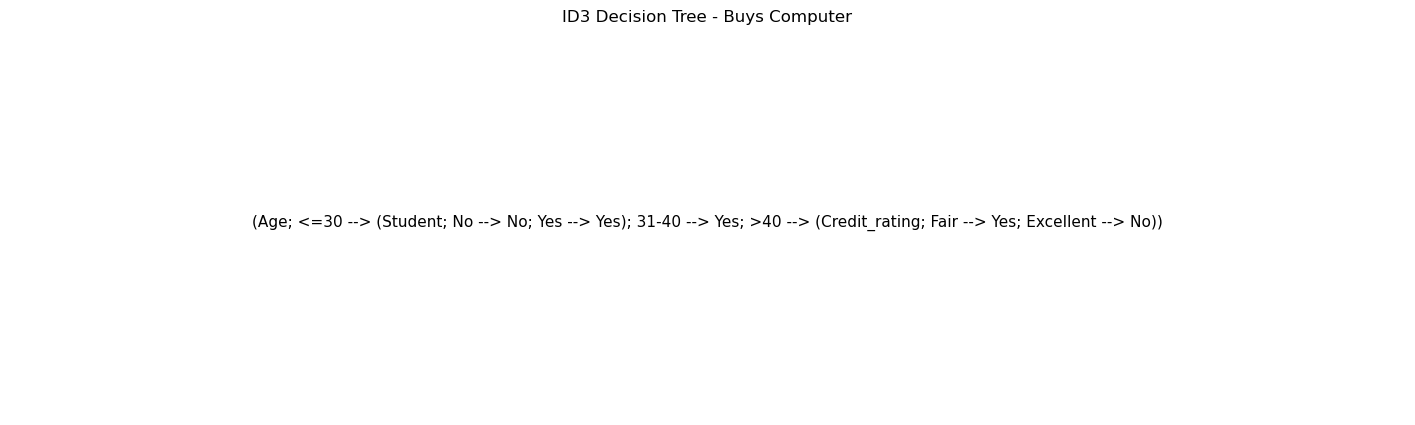

In [9]:
def draw_tree(tree, depth=0):
    if not isinstance(tree, dict):
        return str(tree)

    attribute = next(iter(tree))
    lines = [attribute]

    for value, subtree in tree[attribute].items():
        child_text = draw_tree(subtree, depth + 1)
        lines.append(f"{value} --> {child_text}")

    return "(" + "; ".join(lines) + ")"


tree_text = draw_tree(decision_tree)

plt.figure(figsize=(18, 5))
plt.axis('off')
plt.text(
    0.5, 0.5,
    tree_text,
    ha='center',
    va='center',
    fontsize=11,
    wrap=True
)
plt.title("ID3 Decision Tree - Buys Computer")
plt.show()

In [10]:
def predict_id3(instance, tree):

    if not isinstance(tree, dict):
        return tree

    attribute = next(iter(tree))
    value = instance[attribute]

    if value in tree[attribute]:
        return predict_id3(
            instance,
            tree[attribute][value]
        )

    return df['Buys'].mode()[0]


predictions = []

for _, row in df.iterrows():
    instance = row.drop('Buys').to_dict()
    predictions.append(predict_id3(instance, decision_tree))

df_results = df.copy()
df_results['Predicted_Buys'] = predictions

display(df_results)

accuracy = accuracy_score(df['Buys'], predictions)

print("Training Accuracy:", round(accuracy * 100, 2), "%")

,Age,Income,Student,Credit_rating,Buys,Predicted_Buys
0,<=30,High,No,Fair,No,No
1,<=30,High,No,Excellent,No,No
2,31-40,High,No,Fair,Yes,Yes
3,>40,Medium,No,Fair,Yes,Yes
4,>40,Low,Yes,Fair,Yes,Yes
5,>40,Low,Yes,Excellent,No,No
6,31-40,Low,Yes,Excellent,Yes,Yes
7,<=30,Medium,No,Fair,No,No
8,<=30,Low,Yes,Fair,Yes,Yes
9,>40,Medium,Yes,Fair,Yes,Yes


Training Accuracy: 100.0 %


In [12]:
print("=== BUY COMPUTER PREDICTION SYSTEM ===")

age = input("Enter Age (<=30 / 31-40 / >40): ").strip()
income = input("Enter Income (High / Medium / Low): ").strip().capitalize()
student = input("Is the customer a student? (Yes / No): ").strip().capitalize()
credit = input("Enter Credit Rating (Fair / Excellent): ").strip().capitalize()

# Normalize age input
age = age.replace(" ", "")

if age in ["<=30", "≤30"]:
    age = "<=30"
elif age in ["31-40", "31...40", "31–40"]:
    age = "31-40"
elif age in [">40", ">40"]:
    age = ">40"

# Validate input
if age not in ["<=30", "31-40", ">40"]:
    print("Invalid age category!")
elif income not in ["High", "Medium", "Low"]:
    print("Invalid income!")
elif student not in ["Yes", "No"]:
    print("Invalid student value!")
elif credit not in ["Fair", "Excellent"]:
    print("Invalid credit rating!")
else:
    customer = {
        "Age": age,
        "Income": income,
        "Student": student,
        "Credit_rating": credit
    }

    result = predict_id3(customer, decision_tree)

    print("\n=== CLASSIFICATION RESULT ===")
    print("Customer details:", customer)
    print("Predicted class: Buys =", result)

    if result == "Yes":
        print("Conclusion: The customer is predicted to buy a computer.")
    else:
        print("Conclusion: The customer is predicted NOT to buy a computer.")

=== BUY COMPUTER PREDICTION SYSTEM ===

=== CLASSIFICATION RESULT ===
Customer details: {'Age': '<=30', 'Income': 'Medium', 'Student': 'Yes', 'Credit_rating': 'Excellent'}
Predicted class: Buys = Yes
Conclusion: The customer is predicted to buy a computer.
